# Лабораторная работа № 5. Нечёткая логика
**Цель** — реализовать вывод Мамдани в задаче расчёта чаевых и исследовать влияние оценок сервиса и еды.

Откройте файл в Google Colab и выберите **Среда выполнения → Выполнить все**. Дополнительные данные и GPU не требуются.

Сначала воспроизводится модель из задания. Затем оценки переводятся со шкалы **0–10** на **0–20**, а диапазон чаевых меняется с **0–25 %** на **5–35 %**. Правила и относительная форма функций принадлежности сохраняются, чтобы измерить эффект смены шкал.

In [ ]:
%pip install -q simpful==2.7.0

## 1. Переменные, термы и правила
Входы — оценки сервиса $s$ и еды $f$ в баллах. Выход $t$ — чаевые в процентах от счёта. Терм задаётся функцией принадлежности со значениями от 0 до 1. При перекрытии термов одна оценка может активировать несколько правил.

| Переменная | Терм | Узлы исходной функции |
|:--|:--|:--|
| Сервис | плохой / хороший / отличный | (0, 0, 5) / (0, 5, 10) / (5, 10, 10) |
| Еда | невкусная / вкусная | (0, 0, 10) / (0, 10, 10) |
| Чаевые | малые / средние / щедрые | (0, 0, 10) / (0, 10, 20) / (10, 20, 25, 25) |

Три узла задают треугольник, четыре — трапецию. Повтор крайнего узла задаёт плечо на границе шкалы. Новые узлы получаются по формулам $x'=2x$ для обеих оценок и $t'=5+1.2t$ для чаевых.

1. Плохой сервис **ИЛИ** невкусная еда → малые чаевые.
2. Хороший сервис → средние чаевые.
3. Отличный сервис **ИЛИ** вкусная еда → щедрые чаевые.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from simpful import FuzzySet, FuzzySystem, LinguisticVariable, Trapezoidal_MF, Triangular_MF

TERMS = {
    "Service": {"poor": (0, 0, 5), "good": (0, 5, 10), "excellent": (5, 10, 10)},
    "Food": {"rancid": (0, 0, 10), "delicious": (0, 10, 10)},
    "Tip": {"small": (0, 0, 10), "average": (0, 10, 20), "generous": (10, 20, 25, 25)},
}
RANGES = {"Service": (0, 10), "Food": (0, 10), "Tip": (0, 25)}
RULES = [
    "IF (Service IS poor) OR (Food IS rancid) THEN (Tip IS small)",
    "IF (Service IS good) THEN (Tip IS average)",
    "IF (Service IS excellent) OR (Food IS delicious) THEN (Tip IS generous)",
]
SUBDIVISIONS = 1001


def build_system(input_scale=1, tip_scale=1, tip_offset=0):
    system = FuzzySystem(show_banner=False)
    sets, domains = {}, {}
    for variable, terms in TERMS.items():
        scale, offset = (tip_scale, tip_offset) if variable == "Tip" else (input_scale, 0)
        domains[variable] = [offset + scale * x for x in RANGES[variable]]
        sets[variable] = {}
        for term, nodes in terms.items():
            mf = Triangular_MF if len(nodes) == 3 else Trapezoidal_MF
            sets[variable][term] = FuzzySet(
                function=mf(*(offset + scale * node for node in nodes)), term=term
            )
        system.add_linguistic_variable(
            variable, LinguisticVariable(list(sets[variable].values()),
                                         universe_of_discourse=domains[variable])
        )
    system.add_rules(RULES)
    return system, sets, domains


def predict(system, service, food):
    system.set_variable("Service", float(service))
    system.set_variable("Food", float(food))
    return system.Mamdani_inference(["Tip"], subdivisions=SUBDIVISIONS)["Tip"]


base, base_sets, base_domains = build_system()
model, new_sets, new_domains = build_system(input_scale=2, tip_scale=1.2, tip_offset=5)
print(f"Исходная модель при (4, 8): {predict(base, 4, 8):.4f} %")
print(f"Новая модель при (8, 16):    {predict(model, 8, 16):.4f} %")

Исходная модель при (4, 8): 14.1722 %
Новая модель при (8, 16):    22.0067 %


## 2. Функции принадлежности на двух шкалах
Высота кривой показывает степень принадлежности, а горизонтальная координата — оценку в баллах или чаевые в процентах. При смене шкал меняются координаты узлов. Например, у средних чаевых узлы (0, 10, 20) превращаются в (5, 17, 29).

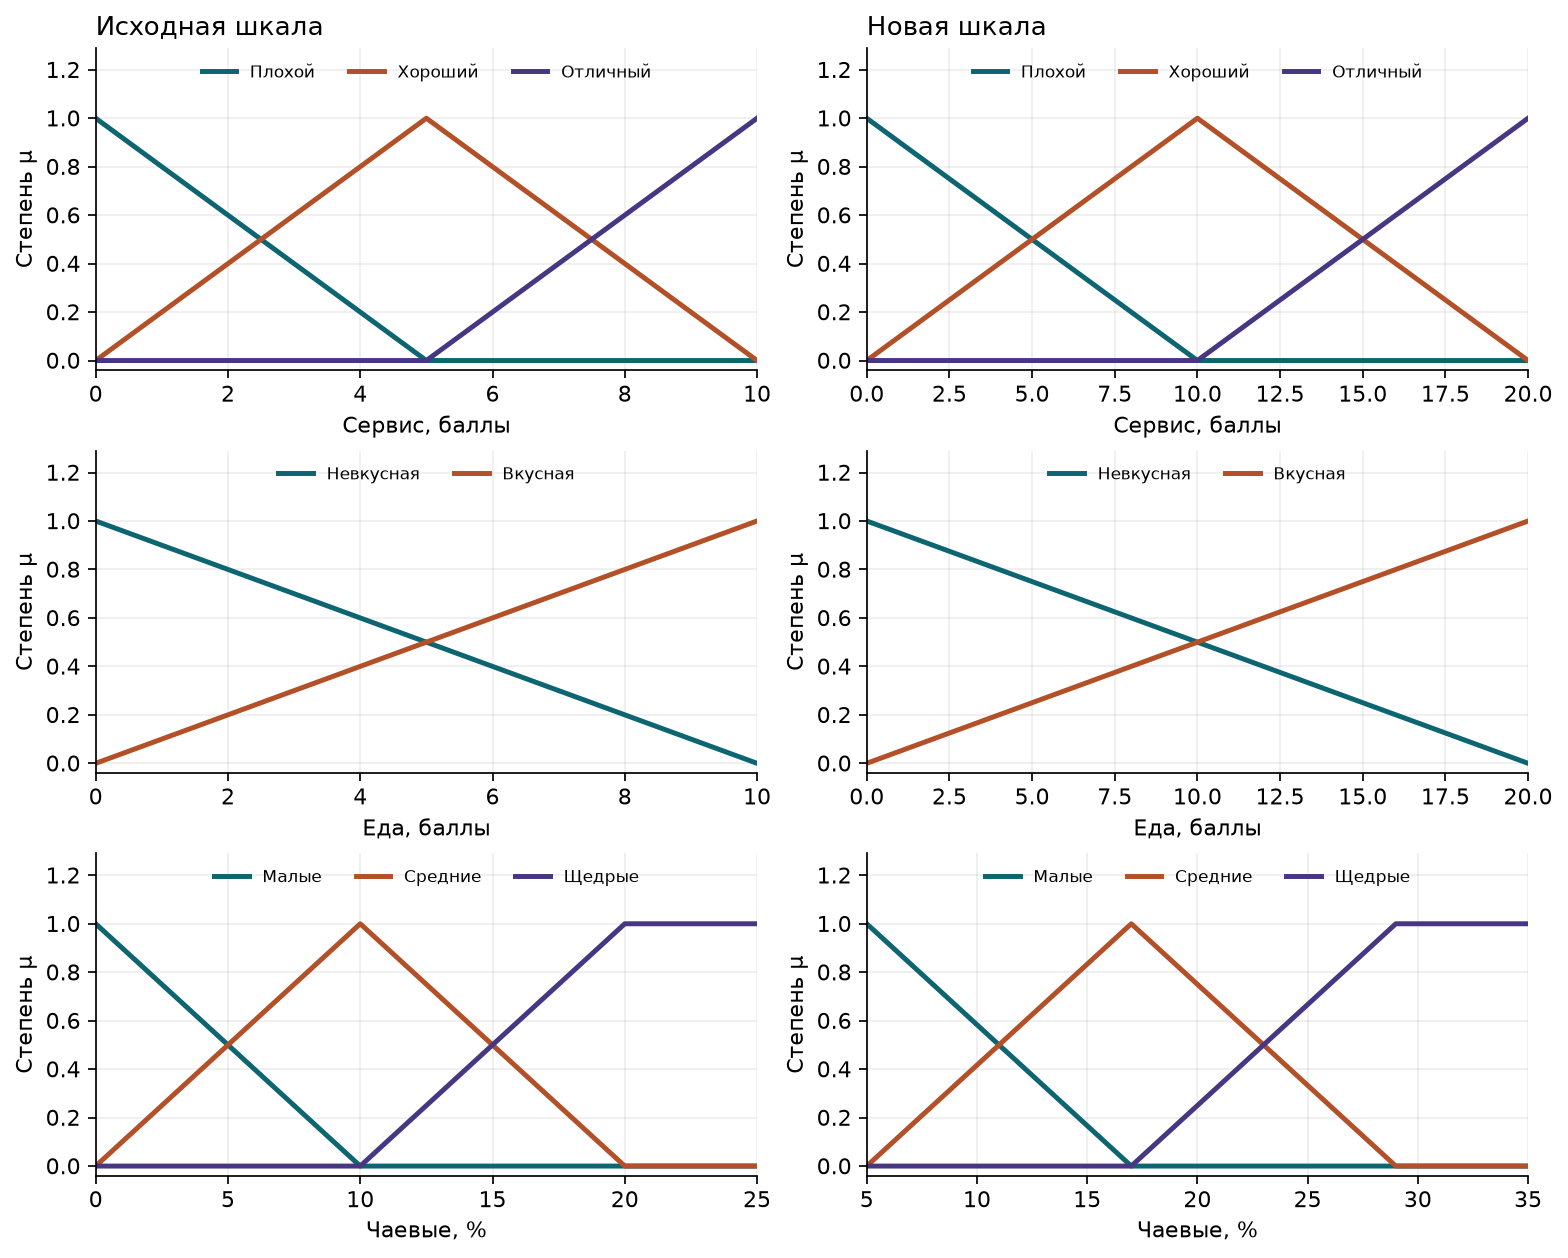

In [3]:
LABELS = {
    "poor": "Плохой", "good": "Хороший", "excellent": "Отличный",
    "rancid": "Невкусная", "delicious": "Вкусная",
    "small": "Малые", "average": "Средние", "generous": "Щедрые",
}
COLORS = ("#0c6571", "#b35027", "#473682")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.22, "axes.axisbelow": True})

fig, axes = plt.subplots(3, 2, figsize=(10, 8), layout="constrained")
for row, (variable, label) in enumerate([("Service", "Сервис, баллы"),
                                         ("Food", "Еда, баллы"),
                                         ("Tip", "Чаевые, %")]):
    for col, (sets, domains, title) in enumerate([
        (base_sets, base_domains, "Исходная шкала"),
        (new_sets, new_domains, "Новая шкала"),
    ]):
        ax = axes[row, col]
        x = np.linspace(*domains[variable], 401)
        for (term, fuzzy_set), color in zip(sets[variable].items(), COLORS):
            ax.plot(x, [fuzzy_set.get_value(v) for v in x],
                    lw=2.3, color=color, label=LABELS[term])
        ax.set(xlabel=label, ylabel="Степень μ", xlim=domains[variable], ylim=(-.04, 1.29))
        if row == 0:
            ax.set_title(title, loc="left")
        ax.legend(loc="upper center", ncol=3, frameon=False, fontsize=8)
plt.show()

## 3. Один вывод по шагам
Для $(s,f)=(8,16)$ сервис имеет степени $(0.2,0.8,0)$, еда — $(0.2,0.8)$. В правилах используется ИЛИ = максимум, поэтому силы трёх правил равны $(0.2,0.8,0.8)$. Каждая выходная функция обрезается на высоте своего правила: $\mu_i^*(t)=\min(\alpha_i,\mu_i(t))$. Объединение — верхняя огибающая $\mu_\Sigma(t)=\max_i\mu_i^*(t)$.

Центроид вычисляется на равномерной сетке $\hat t=\sum_j t_j\mu_\Sigma(t_j)/\sum_j\mu_\Sigma(t_j)$. Ниже этот расчёт повторён напрямую и сравнен с библиотекой.

Силы правил: {'small': 0.2, 'average': 0.8, 'generous': 0.8}
Центроид: 22.0067 %


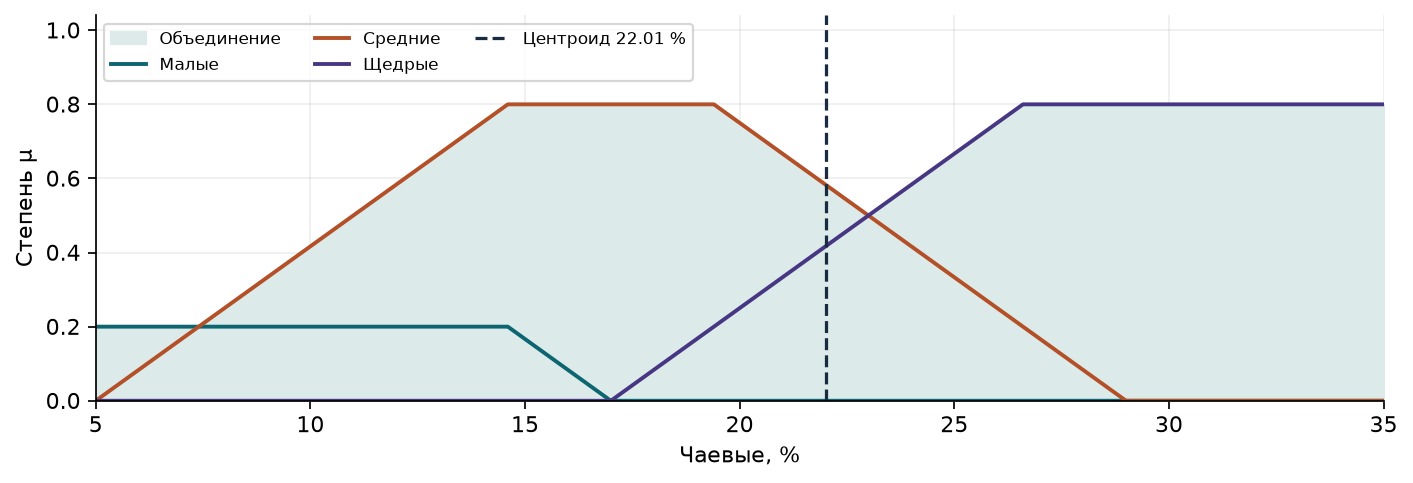

In [4]:
s, f = 8, 16
service_mu = {name: term.get_value(s) for name, term in new_sets["Service"].items()}
food_mu = {name: term.get_value(f) for name, term in new_sets["Food"].items()}
strengths = {
    "small": max(service_mu["poor"], food_mu["rancid"]),
    "average": service_mu["good"],
    "generous": max(service_mu["excellent"], food_mu["delicious"]),
}
t = np.linspace(*new_domains["Tip"], SUBDIVISIONS)
clipped = {
    name: np.minimum(strengths[name], [term.get_value(v) for v in t])
    for name, term in new_sets["Tip"].items()
}
aggregate = np.maximum.reduce(list(clipped.values()))
assert aggregate.sum() > 0
manual = np.dot(t, aggregate) / aggregate.sum()
assert np.isclose(manual, predict(model, s, f), atol=1e-10, rtol=0)
print("Силы правил:", {name: round(value, 2) for name, value in strengths.items()})
print(f"Центроид: {manual:.4f} %")

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.fill_between(t, aggregate, color="#dcebea", label="Объединение")
for (name, curve), color in zip(clipped.items(), COLORS):
    ax.plot(t, curve, lw=1.8, color=color, label=LABELS[name])
ax.axvline(manual, ls="--", color="#182b40", label=f"Центроид {manual:.2f} %")
ax.set(xlim=new_domains["Tip"], ylim=(0, 1.04), xlabel="Чаевые, %", ylabel="Степень μ")
ax.legend(ncol=3, fontsize=8)
plt.show()

## 4. Зависимости чаевых от сервиса и еды
График по сервису строится при фиксированных оценках еды 0, 10 и 20. График по еде строится при фиксированных оценках сервиса 0, 10 и 20. По изменяемой оценке используются 81 равномерно расположенная точка.

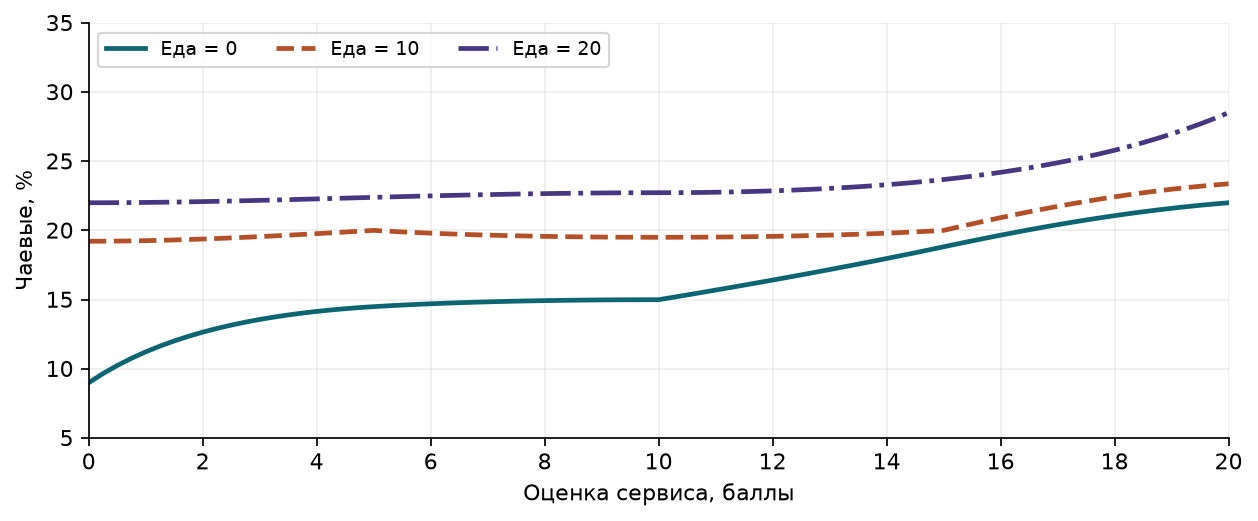

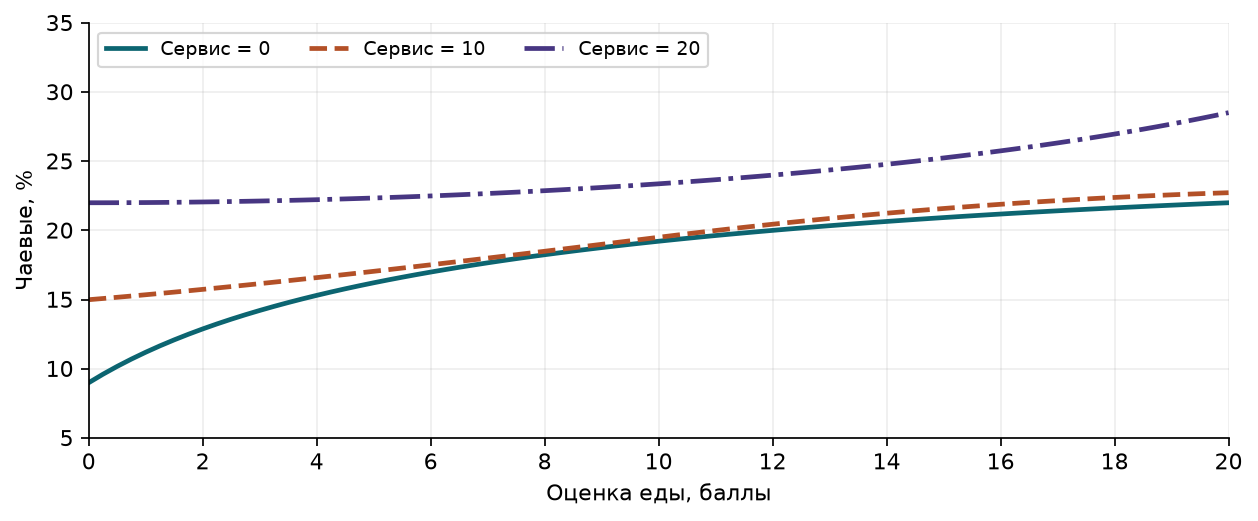

In [5]:
scores = np.linspace(0, 20, 81)
fixed = (0, 10, 20)
service_curves = {food: np.array([predict(model, service, food) for service in scores])
                  for food in fixed}
food_curves = {service: np.array([predict(model, service, food) for food in scores])
               for service in fixed}

for curves, xlabel, fixed_label in [
    (service_curves, "Оценка сервиса, баллы", "Еда"),
    (food_curves, "Оценка еды, баллы", "Сервис"),
]:
    fig, ax = plt.subplots(figsize=(8, 3.25), layout="constrained")
    for (score, tips), color, linestyle in zip(curves.items(), COLORS, ("-", "--", "-.")):
        ax.plot(scores, tips, lw=2.2, color=color, ls=linestyle, label=f"{fixed_label} = {score}")
    ax.set(xlabel=xlabel, ylabel="Чаевые, %", xlim=(0, 20), ylim=(5, 35),
           xticks=np.arange(0, 21, 2))
    ax.legend(loc="upper left", ncol=3, fontsize=9)
    plt.show()

## 5. Проверка, интерпретация и вывод
Сопоставим модели на одинаковых относительных оценках и проверим диапазон всех рассчитанных кривых. Таблица ниже показывает проценты для девяти сочетаний оценок.

In [6]:
for curves in (service_curves, food_curves):
    for values in curves.values():
        assert np.isfinite(values).all() and np.all((5 <= values) & (values <= 35))

grid = [[predict(model, service, food) for food in fixed] for service in fixed]
for service, row in zip(fixed, grid):
    for food, tip in zip(fixed, row):
        assert np.isclose(tip, 5 + 1.2 * predict(base, service / 2, food / 2),
                          atol=1e-10, rtol=0)
print("Сервис / еда |     0     10     20")
for service, row in zip(fixed, grid):
    print(f"{service:12} |" + "".join(f"{value:7.2f}" for value in row))
print("Проверки завершены.")

Сервис / еда |     0     10     20
           0 |   8.99  19.22  22.00
          10 |  14.99  19.50  22.72
          20 |  22.00  23.37  28.51
Проверки завершены.


При сервисе 10 улучшение еды с 0 до 20 меняет чаевые с **14.99 %** до **22.72 %**. При еде 10 рост оценки сервиса с 5 до 10 снижает чаевые с **20.00 %** до **19.50 %**. Силы правил малых и щедрых чаевых на этом отрезке равны 0,5. Сила среднего правила растёт с 0,5 до 1, добавляя к огибающей массу с центром в 17 %, левее прежнего центроида. Поэтому итог смещается влево.

**Вывод.** Построены функции принадлежности сервиса, еды и чаевых, изменены входные и выходная шкалы и исследованы два семейства сечений. Для оценок (8, 16) модель выдаёт **22.0067 %**. Вывод библиотеки совпал с расчётом по шагам. Поведение модели определяется выбранными правилами и термами.